# Цель работы:

Изучение методов кластерного анализа на примере алгоритма K-средних, а также приобретение навыков рефакторинга кода и определения оптимального количества кластеров.

# Задание:

1.	Реализация кластерного анализа на языке Python с использованием библиотек scikit-learn и pandas.
2.	Исследование методов определения оптимального числа кластеров (метод локтя).
3.	Интерпретация результатов кластеризации для различных значений K.

# Теоретическая часть

## Ответы на контрольные вопросы:

1. Кластерный анализ — метод машинного обучения для группировки объектов в кластеры на основе их схожести.

2. Методы кластерного анализа:

    - K-средних (K-Means).

    - Иерархическая кластеризация.

    - DBSCAN.

3. Используемые классы и функции Python:

    - KMeans из sklearn.cluster.

    - pandas для обработки данных.

    - matplotlib для визуализации.

4. Определение оптимального числа кластеров:
Метод локтя — анализ графика зависимости суммы квадратов расстояний (WCSS) от числа кластеров.

5. Отличия методов:

    - Кластеризация: группировка без меток.

    - Классификация: предсказание меток.

    - Регрессия: предсказание непрерывных значений.

# Практическая часть

## Описание данных

Используемый датасет: airline_passenger-satisfaction.csv (25977 наченией)

Использованы 5 ключевых признаков:

- Age – возраст пассажира

- Flight Distance – расстояние полета (км)

- Seat comfort – оценка комфорта сидений (1-5)

- Food and drink – оценка питания (1-5)

- Inflight entertainment – оценка развлечений (1-5)

## Подключение нужных библиотек

In [1]:
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns

# Настройка отображения
pd.set_option('display.max_columns', None)
%matplotlib inline

## Предобработка данных

In [2]:
# Загрузка данных
df = pd.read_csv('airline_passenger_satisfaction.csv')

# Просмотр структуры данных
print(f"Размер датасета: {df.shape}")

# Проверка пропущенных значений
print("\nКоличество пропущенных значений:")
print(df.isna().sum())

# Выбор признаков для кластеризации
features = ['Age', 'Flight Distance', 'Seat comfort', 'Food and drink', 'Inflight entertainment']
X = df[features].dropna()

# Нормализация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Создание чистого датафрейма
df_clean = df.dropna(subset=features).copy()
print(f"\nРазмер данных после очистки: {df_clean.shape}")

Размер датасета: (25976, 25)

Количество пропущенных значений:
Unnamed: 0                            0
id                                    0
Gender                                0
Customer Type                         0
Age                                   0
Type of Travel                        0
Class                                 0
Flight Distance                       0
Inflight wifi service                 0
Departure/Arrival time convenient     0
Ease of Online booking                0
Gate location                         0
Food and drink                        0
Online boarding                       0
Seat comfort                          0
Inflight entertainment                0
On-board service                      0
Leg room service                      0
Baggage handling                      0
Checkin service                       0
Inflight service                      0
Cleanliness                           0
Departure Delay in Minutes            0
Arrival Delay in 

## Определение оптимального числа кластеров

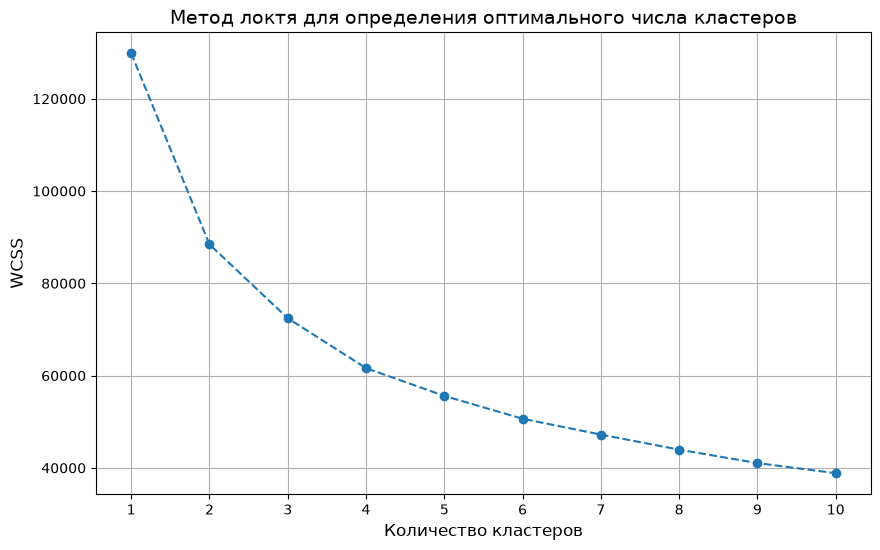

In [3]:
#| fig-cap: "Метод локтя для определения оптимального числа кластеров"
# Вычисление WCSS для разных значений K
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Визуализация метода локтя
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Метод локтя для определения оптимального числа кластеров', fontsize=14)
plt.xlabel('Количество кластеров', fontsize=12)
plt.ylabel('WCSS', fontsize=12)
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Для подробного сравнения выбрано K=3. Метод локтя носит эвристический характер и сам по себе не доказывает оптимальность этого значения.

## Анализ результатов для разных K
### Кластеризация при оптимальном количестве кластеров (K=3)

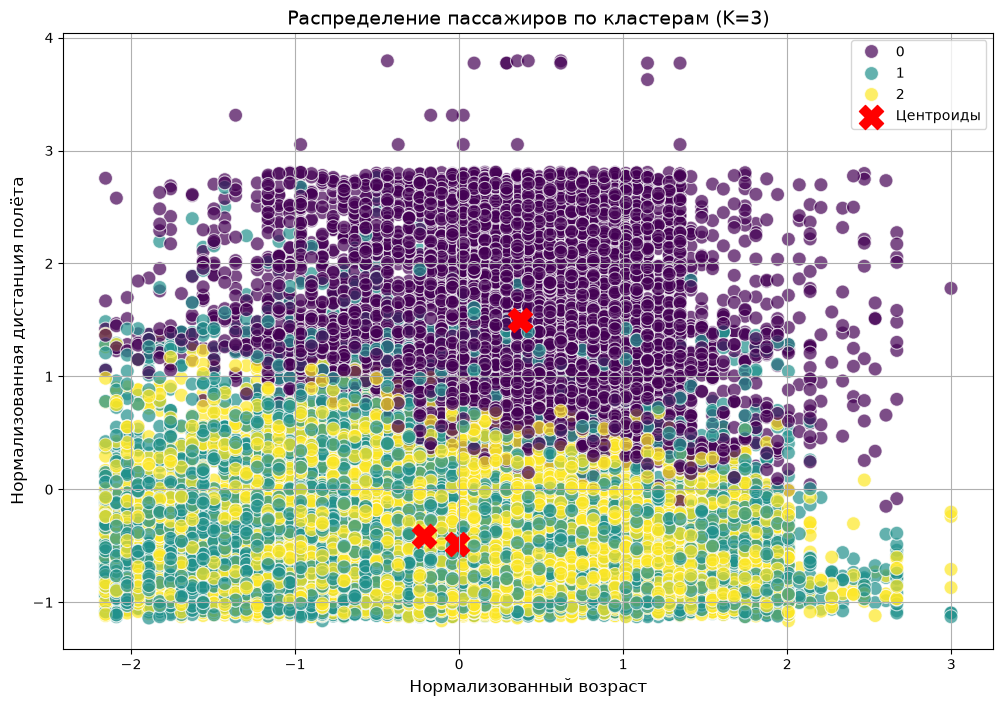


Средние значения признаков:


,Age,Flight Distance,Seat comfort,Food and drink,Inflight entertainment
Cluster,,,,,
0,45.273519,2692.261801,4.010211,3.420656,3.849849
1,36.406167,782.003267,2.266285,2.094037,2.129875
2,39.397335,711.925647,4.255878,4.171042,4.247845


In [4]:
#| fig-cap: "Распределение пассажиров по кластерам при K = 3"
#| tbl-cap: "Средние значения признаков по кластерам при K = 3"
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_clean['Cluster'] = clusters

# Визуализация
plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters, 
                palette='viridis', alpha=0.7, s=100)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=300, c='red', marker='X', label='Центроиды')
plt.title(f'Распределение пассажиров по кластерам (K={k})', fontsize=14)
plt.xlabel('Нормализованный возраст', fontsize=12)
plt.ylabel('Нормализованная дистанция полёта', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

# Характеристики кластеров
print("\nСредние значения признаков:")
display(df_clean.groupby('Cluster')[features].mean().style.background_gradient(cmap='Blues'))

### Кластеризация при дургих значениях K

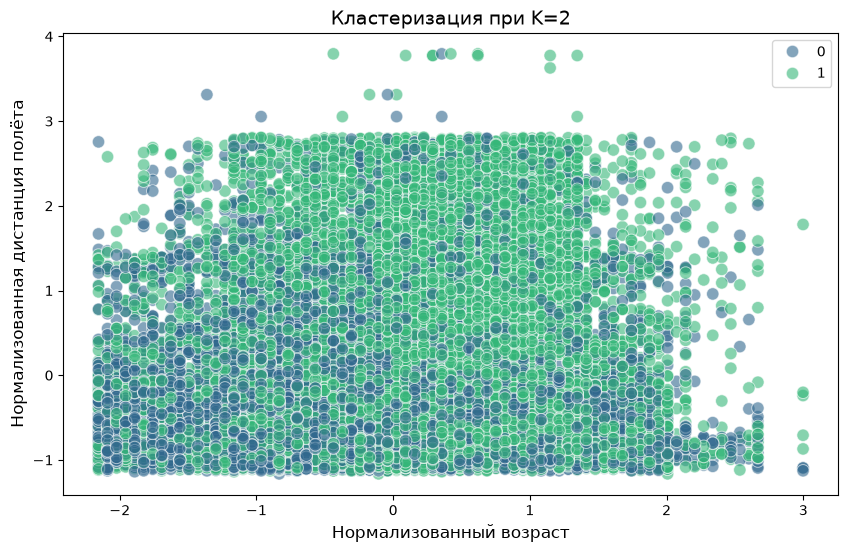


Средние характеристики для K=2:


,Age,Flight Distance,Seat comfort,Food and drink,Inflight entertainment
Cluster,,,,,
0,36.535728,928.049944,2.318743,2.130471,2.182566
1,41.779246,1379.687189,4.240055,3.974287,4.179861


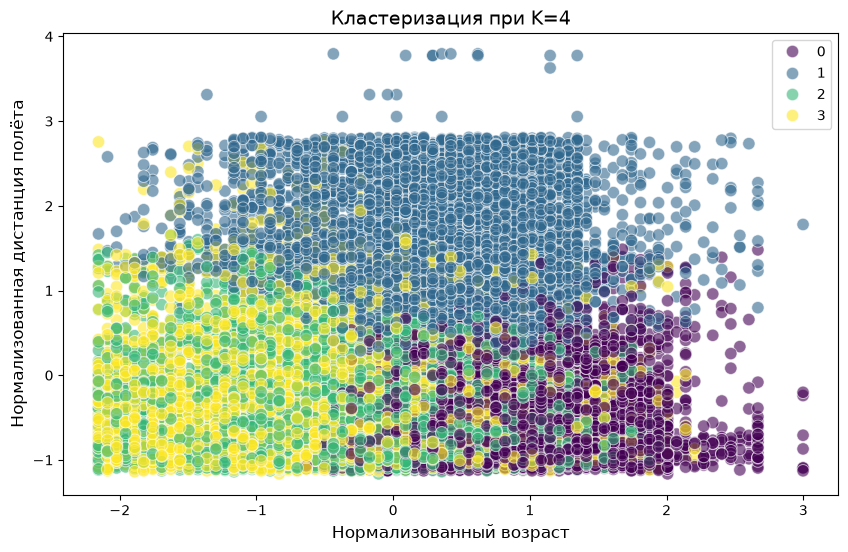


Средние характеристики для K=4:


,Age,Flight Distance,Seat comfort,Food and drink,Inflight entertainment
Cluster,,,,,
0,53.038082,700.869519,3.532696,3.062813,3.140343
1,44.853668,2774.297457,4.022853,3.454110,3.927202
2,32.844667,771.595606,4.359755,4.446391,4.481435
3,29.559397,855.280142,1.940603,1.864509,1.919031


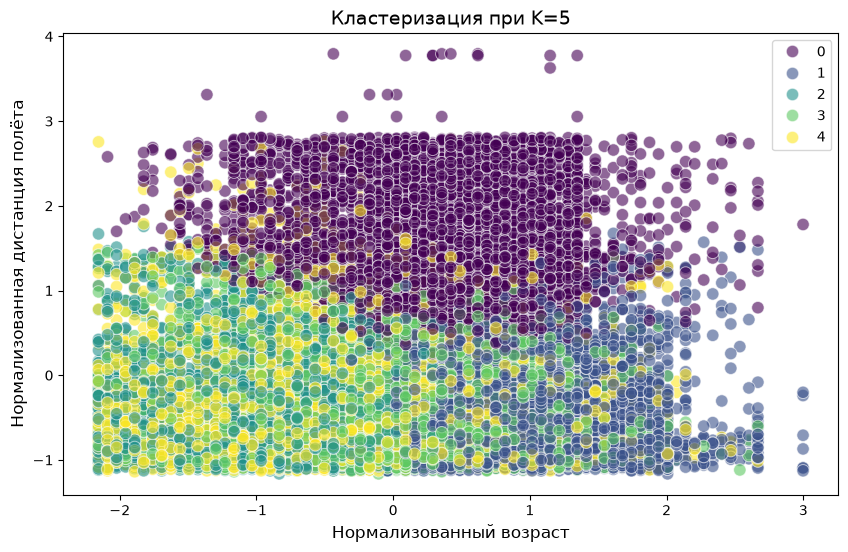


Средние характеристики для K=5:


,Age,Flight Distance,Seat comfort,Food and drink,Inflight entertainment
Cluster,,,,,
0,44.956378,2817.969368,4.019969,3.428848,3.919349
1,54.894120,732.282468,3.554834,2.962843,3.049603
2,25.309847,787.241112,3.305969,3.497738,3.525749
3,38.679723,786.428676,4.631627,4.606850,4.654582
4,31.726283,864.054432,1.630638,1.533826,1.591369


In [5]:
#| fig-cap: ["Кластеризация при K = 2", "Кластеризация при K = 4", "Кластеризация при K = 5"]
#| tbl-cap: ["Средние характеристики кластеров при K = 2", "Средние характеристики кластеров при K = 4", "Средние характеристики кластеров при K = 5"]
for k in [2, 4, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_scaled)
    
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters,
                   palette='viridis', alpha=0.6, s=80)
    plt.title(f'Кластеризация при K={k}', fontsize=14)
    plt.xlabel('Нормализованный возраст', fontsize=12)
    plt.ylabel('Нормализованная дистанция полёта', fontsize=12)
    plt.show()
    
    temp_df = df_clean.copy()
    temp_df['Cluster'] = clusters
    print(f"\nСредние характеристики для K={k}:")
    display(temp_df.groupby('Cluster')[features].mean())

In [6]:
#| tbl-cap: "Сравнение качества кластеризации"
quality = []
for k in [2,3,4,5]:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size=2000, random_state=42)
    quality.append((k,score))
pd.DataFrame(quality, columns=["K","Силуэт"])


,K,Силуэт
0,2,0.288111
1,3,0.269523
2,4,0.255393
3,5,0.231174


# Анализ результатов

Профили кластеров следует читать по рассчитанным средним значениям пяти признаков. Номера кластеров являются условными метками. Возраст и расстояние сами по себе не определяют класс обслуживания или бюджет пассажира.

При увеличении K появляются более узкие группы. Для сравнения рассчитан коэффициент силуэта на фиксированной случайной подвыборке из 2000 наблюдений: чем он выше, тем лучше разделены группы по используемой метрике.

# Выводы

Реализованы очистка данных, стандартизация пяти признаков, метод локтя и сравнение K=2,3,4,5. Приведены средние характеристики кластеров. Выбор числа групп зависит от качества разделения и задачи интерпретации, а не только от формы графика WCSS.
